In [55]:
import pandas as pd

In [56]:
def load_dataframe(path_to_pickle):
    df = pd.read_pickle(path_to_pickle)
    return df

In [57]:
def filter_dataframe(df):
    required_discriminators = ['timeStamp', 'sfn', 'slot', 'rnti', 'physCellId', 'ulTdSchedSubcellData.subcellId',
                               'ulTdSchedSubcellData.numAllocCellPrbUl', 'lcrId']
    df = df[required_discriminators]
    df.dropna(inplace=True)
    df['timeStamp'] = pd.to_datetime(df['timeStamp'])
    return df

In [58]:
# path_to_pickle = "/mnt/etlogs/logs/Sqd68_Cloud_TL/CB007113_B/SBTS00_ENB_9999_221017_000001/20221018_105847/Logs/tti_trace_scenario_1_default_scenario/ttitrace_streaming.pkl"
# path_to_pickle = "/mnt/etlogs/logs/Sqd68_Cloud_TL/CB007113_B/SBTS00_ENB_9999_221017_000001/20221018_144851/Logs/tti_trace_scenario_1_default_scenario/ttitrace_streaming.pkl"
path_to_pickle = "/mnt/etfiles/users/GaneshS/logs/ute/SBTS_Trunk/CB007113_B/20221018-120337-P/CB007113_B/SBTS00_ENB_9999_221009_000005/20221018_120400/Logs/tti_trace_scenario_1_default_scenario/ttitrace_streaming.pkl"

In [59]:
df = load_dataframe(path_to_pickle=path_to_pickle)

In [60]:
df = filter_dataframe(df)

/tmp/ipykernel_19692/771192775.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dropna(inplace=True)
/tmp/ipykernel_19692/771192775.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['timeStamp'] = pd.to_datetime(df['timeStamp'])


In [61]:
# df.reset_index(inplace=True)

In [62]:
df_subcell_0 = df.where(df['ulTdSchedSubcellData.subcellId'] == 0)
df_subcell_0.reset_index(inplace=True)
df_subcell_1 = df.where(df['ulTdSchedSubcellData.subcellId'] == 1)
df_subcell_1.reset_index(inplace=True)
df_subcell_2 = df.where(df['ulTdSchedSubcellData.subcellId'] == 2)
df_subcell_2.reset_index(inplace=True)
df_subcell_pooled = df.where(df['ulTdSchedSubcellData.subcellId'] != 1)
df_subcell_pooled.reset_index(inplace=True)
df_subcell_0.dropna()
df_subcell_1.dropna()
df_subcell_2.dropna()
# df_subcell_pooled.dropna()

,index,timeStamp,sfn,slot,rnti,physCellId,ulTdSchedSubcellData.subcellId,ulTdSchedSubcellData.numAllocCellPrbUl,lcrId
0,12468,2022-10-18 09:10:56.507833,954.0,15.0,15985.0,52.0,2.0,194.0,3.0
1,12469,2022-10-18 09:10:56.507833,954.0,15.0,47833.0,52.0,2.0,194.0,3.0
6,12474,2022-10-18 09:10:56.510333,955.0,0.0,15985.0,52.0,2.0,194.0,3.0
7,12475,2022-10-18 09:10:56.510333,955.0,0.0,47833.0,52.0,2.0,194.0,3.0
15,12480,2022-10-18 09:10:56.512833,955.0,5.0,15985.0,52.0,2.0,194.0,3.0
...,...,...,...,...,...,...,...,...,...
24374,36842,2022-10-18 09:11:16.247833,880.0,15.0,47833.0,52.0,2.0,176.0,3.0
24409,36877,2022-10-18 09:11:16.580333,914.0,0.0,15985.0,52.0,2.0,176.0,3.0
24412,36878,2022-10-18 09:11:16.582833,914.0,5.0,47833.0,52.0,2.0,176.0,3.0
24447,36915,2022-10-18 09:11:16.915333,947.0,10.0,15985.0,52.0,2.0,176.0,3.0


In [63]:
df_subcell_pooled.dropna(inplace=True)

In [64]:
df_subcell_pooled

,index,timeStamp,sfn,slot,rnti,physCellId,ulTdSchedSubcellData.subcellId,ulTdSchedSubcellData.numAllocCellPrbUl,lcrId
0,12468,2022-10-18 09:10:56.507833,954.0,15.0,15985.0,52.0,2.0,194.0,3.0
1,12469,2022-10-18 09:10:56.507833,954.0,15.0,47833.0,52.0,2.0,194.0,3.0
2,12470,2022-10-18 09:10:56.507833,954.0,15.0,53194.0,50.0,0.0,158.0,1.0
3,12471,2022-10-18 09:10:56.507833,954.0,15.0,19506.0,50.0,0.0,158.0,1.0
6,12474,2022-10-18 09:10:56.510333,955.0,0.0,15985.0,52.0,2.0,194.0,3.0
...,...,...,...,...,...,...,...,...,...
24458,36926,2022-10-18 09:11:16.982833,954.0,5.0,53194.0,50.0,0.0,176.0,1.0
24459,36927,2022-10-18 09:11:17.002833,956.0,5.0,53194.0,50.0,0.0,176.0,1.0
24460,36928,2022-10-18 09:11:17.002833,956.0,5.0,19506.0,50.0,0.0,176.0,1.0
24461,36929,2022-10-18 09:11:17.022833,958.0,5.0,19506.0,50.0,0.0,176.0,1.0


In [65]:
df_subcell_re_indexed = df_subcell_pooled.set_index(['timeStamp', 'ulTdSchedSubcellData.subcellId', 'sfn', 'slot'])[['ulTdSchedSubcellData.numAllocCellPrbUl', 'lcrId']]

In [66]:
df_subcell_re_indexed['Average PRB Allocation'] = None



In [67]:
for index in df_subcell_re_indexed.index:
    df_subcell_re_indexed.loc[index, 'Average PRB Allocation'] = df_subcell_re_indexed.loc[index, 'ulTdSchedSubcellData.numAllocCellPrbUl'].mean()


/tmp/ipykernel_19692/1323703097.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  df_subcell_re_indexed.loc[index, 'Average PRB Allocation'] = df_subcell_re_indexed.loc[index, 'ulTdSchedSubcellData.numAllocCellPrbUl'].mean()


In [68]:
df_subcell_without_duplicates = df_subcell_re_indexed.drop_duplicates('Average PRB Allocation')

In [69]:
df_subcell_re_indexed.head(30)

ulTdSchedSubcellData.numAllocCellPrbUl  \
timeStamp                  ulTdSchedSubcellData.subcellId sfn   slot                                           
2022-10-18 09:10:56.507833 2.0                            954.0 15.0                                   194.0   
                                                                15.0                                   194.0   
                           0.0                            954.0 15.0                                   158.0   
                                                                15.0                                   158.0   
2022-10-18 09:10:56.510333 2.0                            955.0 0.0                                    194.0   
                                                                0.0                                    194.0   
                           0.0                            955.0 0.0                                    158.0   
                                                                0.0                                    158.0   
2022-10-18 09:10:56.512833 0.0                            955.0 5.0                                    158.0   
                           2.0                            955.0 5.0                                    194.0   
                                                                5.0                                    194.0   
                           0.0                            955.0 5.0                                    158.0   
2022-10-18 09:10:56.515333 2.0                            955.0 10.0                                   194.0   
                                                                10.0                                   194.0   
                           0.0                            955.0 10.0                                   158.0   
                                                                10.0                                   158.0   
2022-10-18 09:10:56.517833 0.0                            955.0 15.0                                   158.0   
                           2.0                            955.0 15.0                                   194.0   
                                                                15.0                                   194.0   
                           0.0                            955.0 15.0                                   158.0   
2022-10-18 09:10:56.520333 2.0                            956.0 0.0                                    190.0   
                                                                0.0                                    190.0   
                           0.0                            956.0 0.0                                    162.0   
                                                                0.0                                    162.0   
2022-10-18 09:10:56.522833 0.0                            956.0 5.0                                    162.0   
                           2.0                            956.0 5.0                                    190.0   
                                                                5.0                                    190.0   
                           0.0                            956.0 5.0                                    162.0   
2022-10-18 09:10:56.525333 2.0                            956.0 10.0                                   190.0   
                                                                10.0                                   190.0   

                                                                      lcrId  \
timeStamp                  ulTdSchedSubcellData.subcellId sfn   slot          
2022-10-18 09:10:56.507833 2.0                            954.0 15.0    3.0   
                                                                15.0    3.0   
                           0.0                            954.0 15.0    1.0   
                                                                15.0    1.0   
2022-10-18 

In [70]:
prep_plt_df_subcell_0 = df_subcell_without_duplicates[df_subcell_without_duplicates.index.get_level_values(1) == 0]

In [71]:
prep_plt_df_subcell_2 = df_subcell_without_duplicates[df_subcell_without_duplicates.index.get_level_values(1) == 2]

<AxesSubplot: xlabel='timeStamp,ulTdSchedSubcellData.subcellId,sfn,slot'>

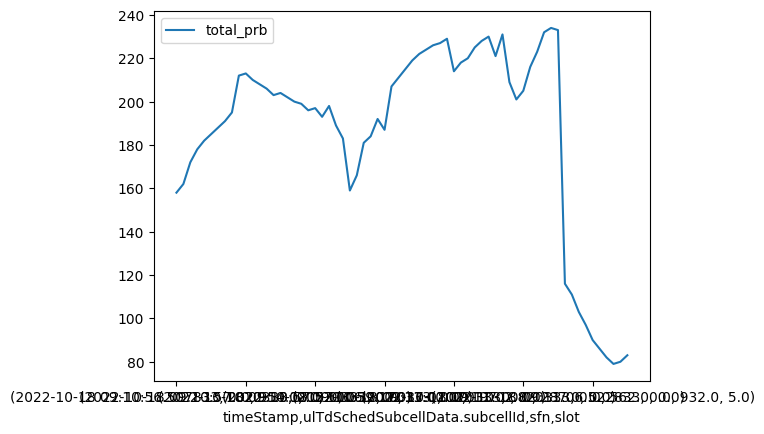

In [72]:
plot_df = pd.DataFrame({'total_prb': prep_plt_df_subcell_0['ulTdSchedSubcellData.numAllocCellPrbUl']}, index=prep_plt_df_subcell_0.index)
plot_df.plot.line()

<AxesSubplot: xlabel='timeStamp,ulTdSchedSubcellData.subcellId,sfn,slot'>

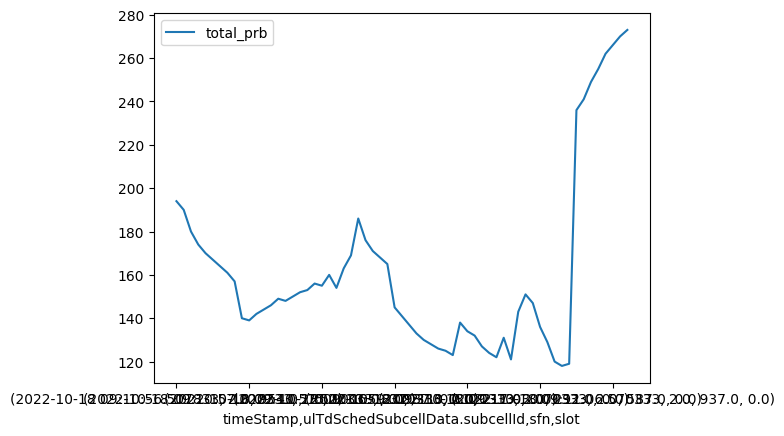

In [73]:
plot_df = pd.DataFrame({'total_prb': prep_plt_df_subcell_2['ulTdSchedSubcellData.numAllocCellPrbUl']}, index=prep_plt_df_subcell_2.index)
plot_df.plot.line()

<AxesSubplot: xlabel='timeStamp,ulTdSchedSubcellData.subcellId,sfn,slot'>

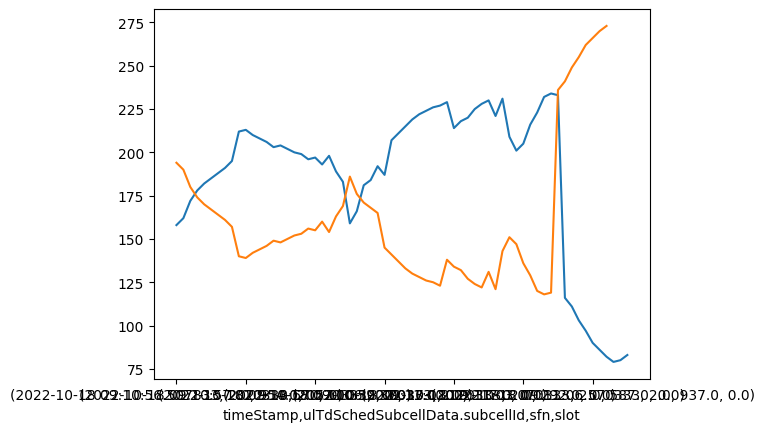

In [74]:
ax = prep_plt_df_subcell_0['ulTdSchedSubcellData.numAllocCellPrbUl'].plot()
prep_plt_df_subcell_2['ulTdSchedSubcellData.numAllocCellPrbUl'].plot(ax=ax)

<AxesSubplot: >

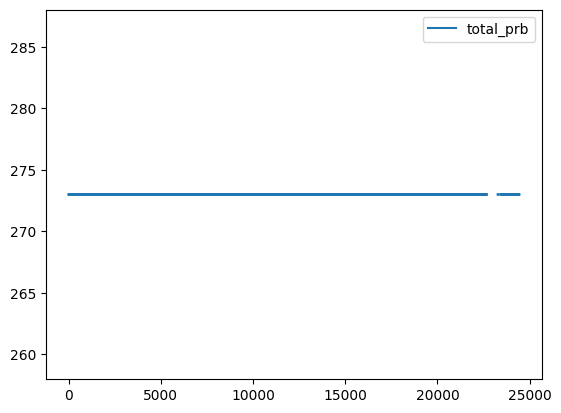

In [75]:
plot_df = pd.DataFrame({'total_prb': df_subcell_1['ulTdSchedSubcellData.numAllocCellPrbUl']}, index=df_subcell_1.index)
plot_df.plot.line()

<AxesSubplot: >

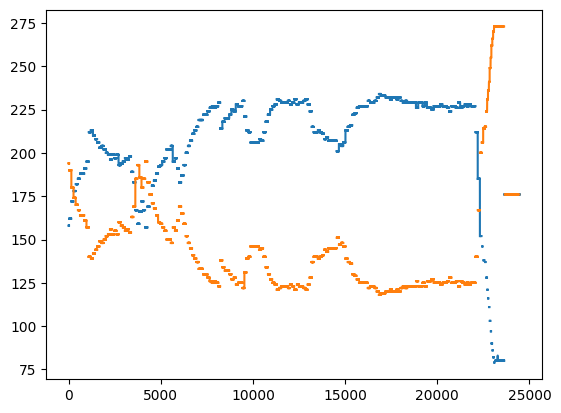

In [76]:
ax = df_subcell_0['ulTdSchedSubcellData.numAllocCellPrbUl'].plot()
df_subcell_2['ulTdSchedSubcellData.numAllocCellPrbUl'].plot(ax=ax)

<AxesSubplot: >

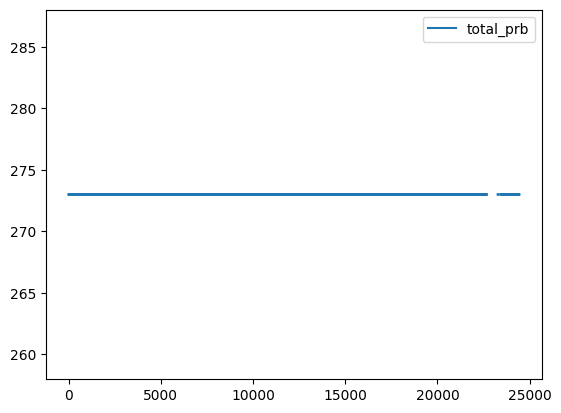

In [77]:
plot_df = pd.DataFrame({'total_prb': df_subcell_1['ulTdSchedSubcellData.numAllocCellPrbUl']}, index=df_subcell_1.index)
plot_df.plot.line()

<AxesSubplot: >

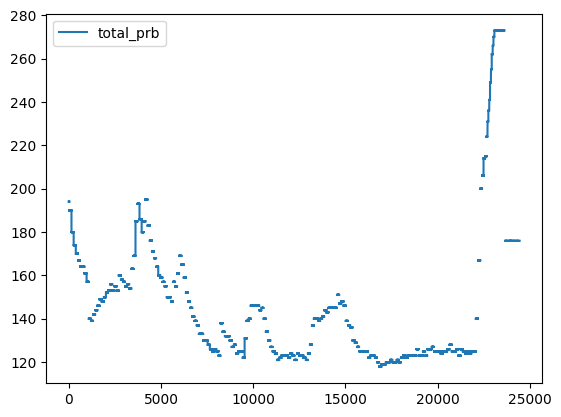

In [78]:
plot_df = pd.DataFrame({'total_prb': df_subcell_2['ulTdSchedSubcellData.numAllocCellPrbUl']}, index=df_subcell_2.index)
plot_df.plot.line()

<AxesSubplot: >

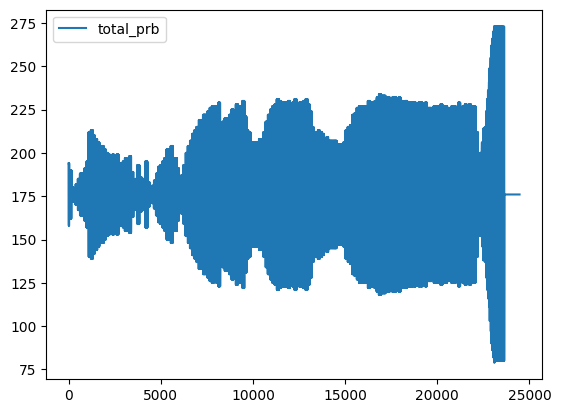

In [79]:
plot_df = pd.DataFrame({'total_prb': df_subcell_pooled['ulTdSchedSubcellData.numAllocCellPrbUl']}, index=df_subcell_pooled.index)
plot_df.plot.line()